In [ ]:
# =============================================================================
# IMPORTS AND ENVIRONMENT CONFIGURATION
# =============================================================================

import iris
import warnings

# Suppress Iris warnings associated with loading model NetCDF files.
# These warnings concern metadata and coordinate conventions and are
# excluded to keep the notebook output focused on the analysis.
from iris.warnings import (IrisLoadWarning, IrisCfNonSpanningVarWarning, IrisCfMissingVarWarning)

warnings.filterwarnings("ignore", category=IrisLoadWarning)
warnings.filterwarnings("ignore", category=IrisCfNonSpanningVarWarning)
warnings.filterwarnings("ignore", category=IrisCfMissingVarWarning)

import numpy as np
import sys
import subprocess
import matplotlib.pyplot as plt
import scipy
from scipy.signal import savgol_filter
from scipy.interpolate import RegularGridInterpolator
from iris.analysis import trajectory
from iris.analysis.cartography import rotate_pole
from pathlib import Path

# Add the project directory to the Python search path so that the custom
# momentum flux analysis functions can be imported.
sys.path.append("/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration")

import momentum_fluxes.momentum_flux_funcs as tx


# =============================================================================
# MODEL DATA AND OROGRAPHY FILEPATHS
# =============================================================================

# Directory containing the orography data used in the model comparison.
orog_data_path_base = "/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/raso_through_model_output/"

# Output file where the orography lives
data_path_orog = "orography_u-eb392_run1_0p3km.nc"

# Original model run filepath. Used for orography inside function to calculate vertical levels
# This is required by the model-processing functions to reconstruct the
# physical heights of the model's vertical levels.
original_model_data_path = "/gws/ssde/j25b/team_x/sidmba/u-eb392_run1/0p3km_v3/w_ALPS_0p3km_ERA5_BAS_MetUM_v3_2s_20250224T1200Z.nc"


# =============================================================================
# RADIOSONDE DATA CONFIGURATION — IOP 17/18
# =============================================================================

# Initialise a container for radiosonde identifiers used later in the analysis.
sonde_ids = []

# Base directory containing three versions of the radiosonde profiles:
#
#   raw_sonde_list    : Original radiosonde observations.
#   coarse_sonde_list : Radiosonde profiles sampled at model levels.
#   model_sonde_list  : Model data interpolated onto sonde trajectory.
#
# These datasets allow subsequent comparisons between the original
# observations, their coarsened counterparts, and the model representation.

# data_path_base = "/gws/ssde/j25b/team_x/TEAMx_FLOW/tbanyard/data/radiosondes/sterzing/202502"
data_path_base = "/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/momentum_fluxes/iop_17_18/" 

# Collect the NetCDF files for each dataset in sorted order.
# Subsequent cells can use a common index to select profiles from each list.
# This assumes that the three lists have corresponding file orderings.
raw_sonde_list = sorted(Path(f"{data_path_base}/iop_17_18_raw_sonde_data").glob("*.nc"))
coarse_sonde_list = sorted(Path(f"{data_path_base}/iop_17_18_coarse_sonde_data").glob("*.nc"))
model_sonde_list = sorted(Path(f"{data_path_base}/iop_17_18_model_sonde_data").glob("*.nc"))

# Select the radiosonde profile to examine in subsequent cells.
# Indexing begins at zero.
index = 3

In [ ]:
# =============================================================================
# SELECT RADIOSONDE AND MODEL DATA FILES
# =============================================================================

# Extract the identifier of the selected radiosonde from its filename.
# This provides a common reference for identifying the observation
# throughout the subsequent analysis.
sonde_id = raw_sonde_list[index].stem[13:21]

# Select the corresponding raw, coarsened, and model-derived profiles.
# All three datasets use the same index, assuming their sorted file lists
# contain matching observations in the same order.
#
# These paths will be passed to the data-loading and processing functions
# to compare momentum flux estimates from the three representations.
raw_data_path = raw_sonde_list[index]
coarse_data_path = coarse_sonde_list[index]
model_data_path = model_sonde_list[index]

# Specify the orography file associated with the model simulation.
# This is needed to determine the terrain height underlying the model data.
data_path_orog = "orography_u-eb392_run1_0p3km.nc"

# Reference to the original model output, used to reconstruct the
# physical heights of the model's vertical levels.
original_model_data_path_4 = "/gws/ssde/j25b/team_x/sidmba/u-eb392_run1/0p3km_v3/w_ALPS_0p3km_ERA5_BAS_MetUM_v3_2s_20250224T1200Z.nc"


In [ ]:
# Import in some data to see what it looks like
plot_title_affix = f"{sonde_id}"
cubelist_m_path = f"{coarse_data_path}"
cubelist_s_path = f"{model_data_path}"
cubelist_r_path = f"{raw_data_path}"

cubelist_mo_path = f"{original_model_data_path}"
orog_cube_path = f"{data_path_base}/{data_path_orog}"

cubelist_s = iris.load(cubelist_s_path)
cubelist_m = iris.load(cubelist_m_path)
cubelist_mo = iris.load(cubelist_mo_path)
orog_cube = iris.load(orog_cube_path)

#cubelist_m

Smoothed Balloon Ascent Rate (m s-1),time
Shape,5676
Dimension coordinates,
time,x
Attributes,
Conventions,'CF-1.13'
acknowledgement,"'Original Level 2 data provided by NCAS, UK'"
averaging_interval,'1 s'
contact,"'T. P. Banyard, tpb38@bath.ac.uk'"
date_created,'2026-09-14 13:10:13 UTC'
deployment_mode,'land'


In [ ]:
# =============================================================================
# EXTRACT ATMOSPHERIC PROFILES FROM THE THREE DATASETS
# =============================================================================

# Extract the variables required for the momentum flux analysis:
# zonal and meridional wind, temperature, potential temperature, and pressure.
#
# Each call returns the valid (non-NaN) values and a corresponding mask
# identifying their positions in the original dataset.
#
# The three datasets represent:
#   s : Sonde data coarsened to model levels 
#   m : Model Data interpolated onto sonde trajectory
#   r : Original (raw) radiosonde observations
#
# These profiles will be used to compare the atmospheric structure and
# derived momentum fluxes across the three representations.

# Coarsened radiosonde profiles
u_s_wind_nonans, u_s_wind_mask = tx.nonans_cubedata(cubelist_s_path, "eastward_wind")
v_s_wind_nonans, v_s_wind_mask = tx.nonans_cubedata(cubelist_s_path, "northward_wind")
T_s_nonans, T_s_mask = tx.nonans_cubedata(cubelist_s_path, "air_temperature")
Theta_s_nonans, Theta_s_mask = tx.nonans_cubedata(cubelist_s_path, "air_potential_temperature")
pressure_s_nonans, pressure_s_mask = tx.nonans_cubedata(cubelist_s_path, "air_pressure")

# Model-derived profiles
u_m_wind_nonans, u_m_wind_mask = tx.nonans_cubedata(cubelist_m_path, "eastward_wind")
v_m_wind_nonans, v_m_wind_mask = tx.nonans_cubedata(cubelist_m_path, "northward_wind")
T_m_nonans, T_m_mask = tx.nonans_cubedata(cubelist_m_path, "air_temperature")
Theta_m_nonans, Theta_m_mask = tx.nonans_cubedata(cubelist_m_path, "air_potential_temperature")
pressure_m_nonans, pressure_m_mask = tx.nonans_cubedata(cubelist_m_path, "air_pressure")

# Original radiosonde profiles
u_r_wind_nonans, u_r_wind_mask = tx.nonans_cubedata(cubelist_r_path, "eastward_wind")
v_r_wind_nonans, v_r_wind_mask = tx.nonans_cubedata(cubelist_r_path, "northward_wind")
T_r_nonans, T_r_mask = tx.nonans_cubedata(cubelist_r_path, "air_temperature")
Theta_r_nonans, Theta_r_mask = tx.nonans_cubedata(cubelist_r_path, "air_potential_temperature")
pressure_r_nonans, pressure_r_mask = tx.nonans_cubedata(cubelist_r_path, "air_pressure")

# Extract altitude and elapsed time from the original radiosonde data.
# These provide the observational coordinates for subsequent comparisons.
alt_nonans, alt_mask = tx.nonans_cubedata(cubelist_r_path, "altitude")
time_nonans, time_mask = tx.nonans_cubedata(cubelist_r_path, "Elapsed Time")


# =============================================================================
# DETERMINE MODEL VERTICAL LEVEL HEIGHTS
# =============================================================================

# Calculate the physical heights of the model's vertical levels along the
# selected radiosonde trajectory, accounting for the model orography.
#
# These heights can be overlaid on subsequent profile plots to illustrate
# the model's vertical sampling relative to the radiosonde observations.
cross_heights = tx.vert_levels_for_sonde(sonde_data_path=cubelist_s_path, 
                                  model_sonde_data_path=cubelist_m_path, 
                                  model_data_path=cubelist_mo_path, 
                                  model_orog_path=orog_cube_path)


In [ ]:
# =============================================================================
# FIT BACKGROUND ATMOSPHERIC PROFILES
# =============================================================================

# Fit polynomial profiles to the wind and thermodynamic variables for the
# coarsened sonde, model sonde, and raw sonde.
#
# These fits represent the slowly varying atmospheric background, which
# will subsequently be subtracted to isolate gravity-wave perturbations.
#
# Fourth-order polynomials are used for wind, temperature, and pressure,
# while fifth-order polynomials are used for potential temperature.
# All profiles are fitted against the same altitude coordinate.

p_deg = 4

# Coarsened sonde
u_s_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, u_s_wind_nonans, p_deg)
v_s_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, v_s_wind_nonans, p_deg)
T_s_coeffs = np.polynomial.Polynomial.fit(alt_nonans, T_s_nonans, p_deg)
pressure_s_coeffs = np.polynomial.Polynomial.fit(alt_nonans, pressure_s_nonans, p_deg)
Theta_s_coeffs = np.polynomial.Polynomial.fit(alt_nonans, Theta_s_nonans, p_deg+1)

# Model sonde
u_m_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, u_m_wind_nonans, p_deg)
v_m_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, v_m_wind_nonans, p_deg)
T_m_coeffs = np.polynomial.Polynomial.fit(alt_nonans, T_m_nonans, p_deg)
pressure_m_coeffs = np.polynomial.Polynomial.fit(alt_nonans, pressure_m_nonans, p_deg)
Theta_m_coeffs = np.polynomial.Polynomial.fit(alt_nonans, Theta_m_nonans, p_deg+1)

# Raw sonde
u_r_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, u_r_wind_nonans, p_deg)
v_r_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, v_r_wind_nonans, p_deg)
T_r_coeffs = np.polynomial.Polynomial.fit(alt_nonans, T_r_nonans, p_deg)
pressure_r_coeffs = np.polynomial.Polynomial.fit(alt_nonans, pressure_r_nonans, p_deg)
Theta_r_coeffs = np.polynomial.Polynomial.fit(alt_nonans, Theta_r_nonans, p_deg+1)


# =============================================================================
# EVALUATE THE BACKGROUND PROFILES
# =============================================================================

# Evaluate the fitted polynomials at the sampled altitudes to obtain
# the background profiles for each variable.
#
# These arrays provide the reference state for calculating perturbations
# and can also be used to compare the large-scale atmospheric structure
# represented by the three datasets.

# Coarsened sonde
u_s_wind_mean = u_s_wind_coeffs(alt_nonans)
v_s_wind_mean = v_s_wind_coeffs(alt_nonans)
T_s_mean = T_s_coeffs(alt_nonans)
pressure_s_mean = pressure_s_coeffs(alt_nonans)
Theta_s_mean = Theta_s_coeffs(alt_nonans)

# Model sonde
u_m_wind_mean = u_m_wind_coeffs(alt_nonans)
v_m_wind_mean = v_m_wind_coeffs(alt_nonans)
T_m_mean = T_m_coeffs(alt_nonans)
pressure_m_mean = pressure_m_coeffs(alt_nonans)
Theta_m_mean = Theta_m_coeffs(alt_nonans)

# Raw sonde
u_r_wind_mean = u_r_wind_coeffs(alt_nonans)
v_r_wind_mean = v_r_wind_coeffs(alt_nonans)
T_r_mean = T_r_coeffs(alt_nonans)
pressure_r_mean = pressure_r_coeffs(alt_nonans)
Theta_r_mean = Theta_r_coeffs(alt_nonans)


# =============================================================================
# CALCULATE ATMOSPHERIC PERTURBATIONS
# =============================================================================

# Subtract the fitted background profiles from the corresponding data
# to obtain perturbations in wind and thermodynamic variables.
#
# Detrending is performed independently for each dataset, allowing the
# perturbation structure retained by the coarsened sonde and model sonde
# to be compared against that of the raw sonde.
#
# The horizontal wind and temperature perturbations are subsequently
# used to calculate gravity-wave momentum fluxes.

# Coarsened sonde
u_s_wind_prime = u_s_wind_nonans - u_s_wind_mean
v_s_wind_prime = v_s_wind_nonans - v_s_wind_mean
T_s_prime = T_s_nonans - T_s_mean
pressure_s_prime = pressure_s_nonans - pressure_s_mean
Theta_s_prime = Theta_s_nonans - Theta_s_mean

# Model sonde
u_m_wind_prime = u_m_wind_nonans - u_m_wind_mean
v_m_wind_prime = v_m_wind_nonans - v_m_wind_mean
T_m_prime = T_m_nonans - T_m_mean
pressure_m_prime = pressure_m_nonans - pressure_m_mean
Theta_m_prime = Theta_m_nonans - Theta_m_mean

# Raw sonde
u_r_wind_prime = u_r_wind_nonans - u_r_wind_mean
v_r_wind_prime = v_r_wind_nonans - v_r_wind_mean
T_r_prime = T_r_nonans - T_r_mean
pressure_r_prime = pressure_r_nonans - pressure_r_mean
Theta_r_prime = Theta_r_nonans - Theta_r_mean


# =============================================================================
# NORMALISE TEMPERATURE PERTURBATIONS
# =============================================================================

# Normalise the temperature perturbations by their respective background
# temperatures to obtain dimensionless perturbation profiles.
#
# These are required for the subsequent momentum flux calculations.

T_hat_s_prime = T_s_prime / T_s_mean
T_hat_m_prime = T_m_prime / T_m_mean
T_hat_r_prime = T_r_prime / T_r_mean


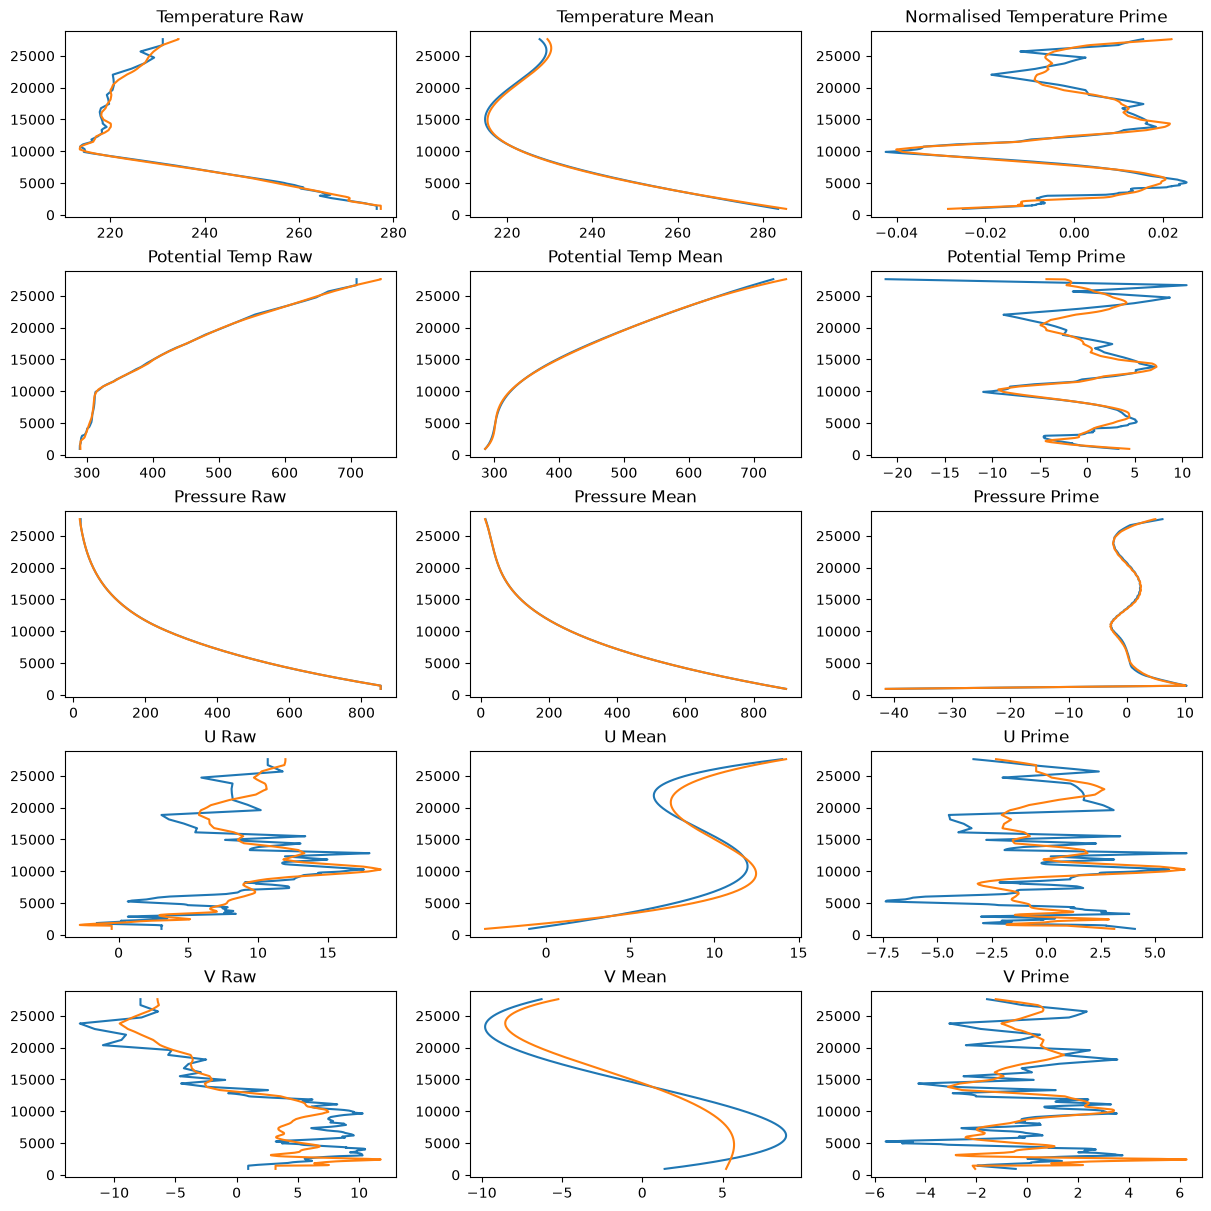

In [ ]:
# =============================================================================
# COMPARE ATMOSPHERIC PROFILES AND THEIR POLYNOMIAL DETRENDING
# =============================================================================

# Generate a 5×3 comparison of the atmospheric variables used in the
# momentum flux analysis.
#
# Each row represents a different variable:
#   Temperature, potential temperature, pressure, zonal wind, meridional wind.
#
# The columns show the original values, fitted background profiles, and
# perturbations obtained by subtracting the background.
#
# Temperature perturbations are normalised by the background temperature,
# whereas the other perturbations retain their original units.
#
# This provides a visual check of the polynomial detrending and highlights
# differences between the coarsened sonde and model sonde before the
# momentum flux calculations.

# Initialise the figure and its 15 panels.
fig = plt.figure(figsize=(12,12), layout="constrained")
ax = fig.subplots(5,3).flatten()

# Organise the profiles in plotting order for each dataset.
# Corresponding entries in the three lists represent the same quantity.

# Coarsened sonde
var_s_list = [T_s_nonans, T_s_mean, T_hat_s_prime, 
              Theta_s_nonans, Theta_s_mean, Theta_s_prime,
              pressure_s_nonans, pressure_s_mean, pressure_s_prime,
              u_s_wind_nonans, u_s_wind_mean, u_s_wind_prime, 
              v_s_wind_nonans, v_s_wind_mean, v_s_wind_prime]

# Model sonde
var_m_list = [T_m_nonans, T_m_mean, T_hat_m_prime, 
              Theta_m_nonans, Theta_m_mean, Theta_m_prime,
              pressure_m_nonans, pressure_m_mean, pressure_m_prime,
              u_m_wind_nonans, u_m_wind_mean, u_m_wind_prime, 
              v_m_wind_nonans, v_m_wind_mean, v_m_wind_prime]

# Raw sonde
var_r_list = [T_r_nonans, T_r_mean, T_hat_r_prime, 
              Theta_r_nonans, Theta_r_mean, Theta_r_prime,
              pressure_r_nonans, pressure_r_mean, pressure_r_prime,
              u_r_wind_nonans, u_r_wind_mean, u_r_wind_prime, 
              v_r_wind_nonans, v_r_wind_mean, v_r_wind_prime]

# Panel titles identifying the atmospheric variable and processing stage.
title_list = ["Temperature Raw", "Temperature Mean", "Normalised Temperature Prime", 
              "Potential Temp Raw", "Potential Temp Mean", "Potential Temp Prime",
              "Pressure Raw", "Pressure Mean", "Pressure Prime",   
              "U Raw", "U Mean", "U Prime", 
              "V Raw", "V Mean", "V Prime"]

# Plot the coarsened sonde and model sonde against altitude.
# The raw sonde profiles are available for comparison but are currently
# excluded from the figure.
#
# Comparing the fitted backgrounds and residual perturbations helps assess
# how differences in sampling and model representation affect the atmospheric
# variability retained for the subsequent momentum flux analysis.
for i,j in enumerate(var_s_list):
    ax[i].plot(var_s_list[i], alt_nonans, color="C0")
    ax[i].plot(var_m_list[i], alt_nonans, color="C1")
    #ax[i].plot(var_r_list[i], alt_nonans, color="C2")
    ax[i].set_title(title_list[i])

plt.show()

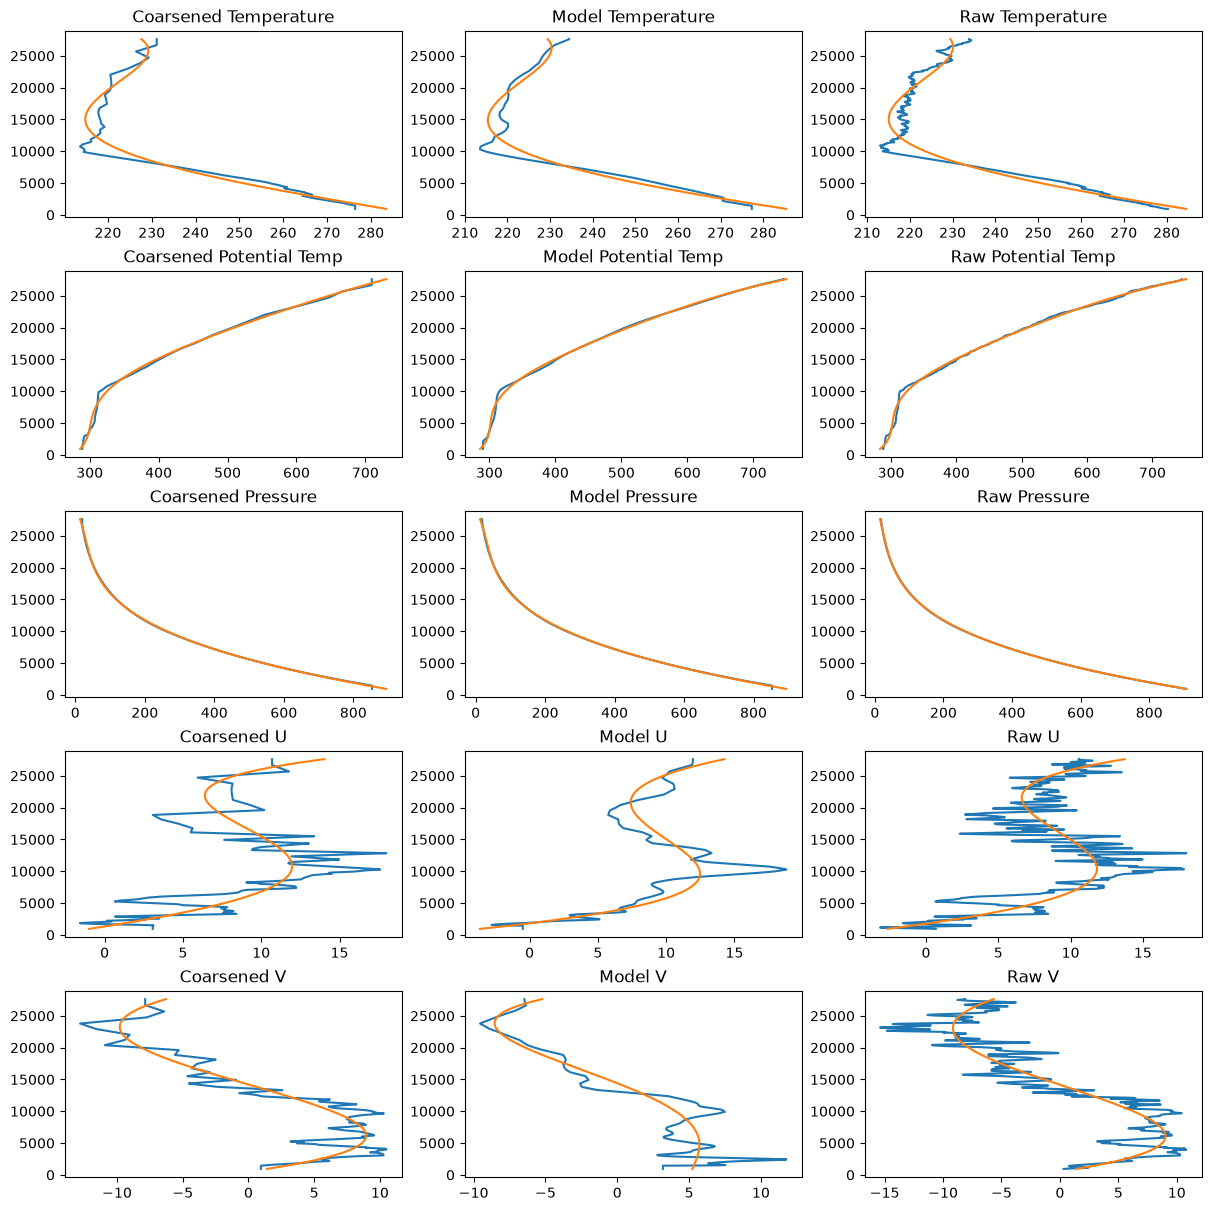

In [ ]:
# =============================================================================
# SANITY CHECK: COMPARE FITTED BACKGROUND PROFILES AGAINST INPUT DATA
# =============================================================================

# Visually assess how well the polynomial background profiles represent
# the atmospheric structure of each dataset.
#
# Each row corresponds to an atmospheric variable, while the columns
# compare the coarsened sonde, model sonde, and raw sonde.
#
# Both the input data and fitted background are plotted against altitude.
# This is particularly useful for checking the potential temperature fit,
# whose vertical gradient is subsequently used to estimate atmospheric
# stability and the Brunt–Väisälä frequency.
#
# The comparison also helps identify whether the polynomial fits capture
# the large-scale structure without following smaller-scale perturbations.

fig = plt.figure(figsize=(12,12), layout="constrained")
ax = fig.subplots(5,3)

# Group each atmospheric variable with its corresponding fitted background.
# The first entry contains the input profile; the second contains the fit.

# Coarsened sonde
var_s_list = [[T_s_nonans, T_s_mean],
              [Theta_s_nonans, Theta_s_mean],
              [pressure_s_nonans, pressure_s_mean],
              [u_s_wind_nonans, u_s_wind_mean],  
              [v_s_wind_nonans, v_s_wind_mean]]

# Model sonde
var_m_list = [[T_m_nonans, T_m_mean],
              [Theta_m_nonans, Theta_m_mean],
              [pressure_m_nonans, pressure_m_mean],
              [u_m_wind_nonans, u_m_wind_mean],  
              [v_m_wind_nonans, v_m_wind_mean]]

# Raw sonde
var_r_list = [[T_r_nonans, T_r_mean],
              [Theta_r_nonans, Theta_r_mean],
              [pressure_r_nonans, pressure_r_mean],
              [u_r_wind_nonans, u_r_wind_mean],  
              [v_r_wind_nonans, v_r_wind_mean]]

# Atmospheric variables displayed in each row.
title_list = ["Temperature", "Potential Temp", "Pressure", "U", "V"]

# Plot the input and fitted background profiles for all three datasets.
# Each column allows the quality of the background fit to be assessed
# independently, while corresponding rows facilitate comparison between
# the different representations of the same atmospheric variable.
for i in range(0, 5):
    ax[i][0].plot(var_s_list[i][0], alt_nonans)
    ax[i][0].plot(var_s_list[i][1], alt_nonans)
    ax[i][0].set_title(f"Coarsened {title_list[i]}")

    ax[i][1].plot(var_m_list[i][0], alt_nonans)
    ax[i][1].plot(var_m_list[i][1], alt_nonans)
    ax[i][1].set_title(f"Model {title_list[i]}")

    ax[i][2].plot(var_r_list[i][0], alt_nonans)
    ax[i][2].plot(var_r_list[i][1], alt_nonans)
    ax[i][2].set_title(f"Raw {title_list[i]}")x[i][2].set_title(f"Raw {title_list[i]}")

In [ ]:
# =============================================================================
# CALCULATE INERTIAL AND BRUNT–VÄISÄLÄ FREQUENCIES
# =============================================================================

# Calculate the Coriolis parameter using the latitude of the raw sonde.
# The same inertial frequency is used for all three datasets, ensuring
# that differences in subsequent calculations arise from their respective
# atmospheric profiles rather than differences in the Coriolis parameter.
f_inertial = tx.coriolis_param_for_sonde(cubelist_r_path)

# Calculate the Brunt–Väisälä frequency for each dataset.
# These values characterise the background stratification represented
# by the coarsened sonde, raw sonde, and model sonde.
N_s = tx.brunt_vaisala_from_sonde(cubelist_s_path)
N_r = tx.brunt_vaisala_from_sonde(cubelist_r_path)
N_m = tx.brunt_vaisala_from_sonde(cubelist_m_path)


# =============================================================================
# ESTIMATE MEAN GRAVITY-WAVE SPECTRAL FREQUENCIES
# =============================================================================

# Estimate the representative intrinsic gravity-wave frequency for each
# dataset using its Brunt–Väisälä frequency and the common inertial frequency.
#
# These frequencies are required for the subsequent momentum flux estimates.
# Differences between them reflect differences in the background stability
# of the three datasets.
omega_bar_s = tx.ave_spectral_frequency(N_s, f_inertial)
omega_bar_m = tx.ave_spectral_frequency(N_m, f_inertial)
omega_bar_r = tx.ave_spectral_frequency(N_r, f_inertial)

/home/users/jmtd42/miniforge3/envs/teamx/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:840: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


Brunt Vaisala Frequency Calculated
Brunt Vaisala Frequency Calculated
Brunt Vaisala Frequency Calculated


In [ ]:
# =============================================================================
# CALCULATE BACKGROUND AIR DENSITY
# =============================================================================

# Estimate air density from the fitted background pressure and temperature
# profiles using the ideal gas equation of state.
#
# Pressure is converted from hPa to Pa, and 287.05 J kg^-1 K^-1 is the
# specific gas constant for dry air.
#
# The resulting density profiles are used to convert the wind-temperature
# correlations into density-weighted quantities for the momentum flux calculation.

rho_s = (pressure_s_mean*100) / (287.05 * T_s_mean)
rho_m = (pressure_m_mean*100) / (287.05 * T_m_mean)
rho_r = (pressure_r_mean*100) / (287.05 * T_r_mean)


# =============================================================================
# CALCULATE PHASE-SHIFTED TEMPERATURE PERTURBATIONS
# =============================================================================

# Apply the Hilbert transform to obtain the quadrature component of the
# normalised temperature perturbations, corresponding to a 90-degree
# phase shift.
#
# These phase-shifted perturbations are required to estimate the
# gravity-wave momentum fluxes from the horizontal wind perturbations.

T_hat_s_prime_90 = np.imag(scipy.signal.hilbert(T_hat_s_prime))
T_hat_m_prime_90 = np.imag(scipy.signal.hilbert(T_hat_m_prime))
T_hat_r_prime_90 = np.imag(scipy.signal.hilbert(T_hat_r_prime))

# Smooth the phase-shifted temperature perturbations using a rolling
# window of 50 samples before constructing the wind-temperature products.
# The smoothing scale is specified in sample points rather than altitude.

T_hat_s_prime_90_smth = tx.rolling_mean(T_hat_s_prime_90, window_size=50)
T_hat_m_prime_90_smth = tx.rolling_mean(T_hat_m_prime_90, window_size=50)
T_hat_r_prime_90_smth = tx.rolling_mean(T_hat_r_prime_90, window_size=50)


# =============================================================================
# CONSTRUCT DENSITY-WEIGHTED WIND-TEMPERATURE PRODUCTS
# =============================================================================

# Multiply the zonal and meridional wind perturbations by the smoothed,
# phase-shifted temperature perturbations and background density.
#
# These products form the quantities whose local averages enter the
# subsequent zonal and meridional momentum flux calculations.

# Coarsened sonde
u_prime_T_hat_prime_rho_s = T_hat_s_prime_90_smth * u_s_wind_prime * rho_s
v_prime_T_hat_prime_rho_s = T_hat_s_prime_90_smth * v_s_wind_prime * rho_s 

# Model sonde
u_prime_T_hat_prime_rho_m = T_hat_m_prime_90_smth * u_m_wind_prime * rho_m
v_prime_T_hat_prime_rho_m = T_hat_m_prime_90_smth * v_m_wind_prime * rho_m

# Raw sonde
u_prime_T_hat_prime_rho_r = T_hat_r_prime_90_smth * u_r_wind_prime * rho_r
v_prime_T_hat_prime_rho_r = T_hat_r_prime_90_smth * v_r_wind_prime * rho_r


# =============================================================================
# AVERAGE THE WIND-TEMPERATURE PRODUCTS
# =============================================================================

# Apply a second rolling mean, again using a 50-sample window, to obtain
# locally averaged density-weighted correlations.
#
# These arrays retain the vertical variation of the correlations while
# suppressing smaller-scale fluctuations. They provide the final
# wind-temperature terms used in the momentum flux estimates.

# Zonal component
uT_hat_mean_s = tx.rolling_mean(u_prime_T_hat_prime_rho_s, window_size=50)
uT_hat_mean_m = tx.rolling_mean(u_prime_T_hat_prime_rho_m, window_size=50)
uT_hat_mean_r = tx.rolling_mean(u_prime_T_hat_prime_rho_r, window_size=50)

# Meridional component
vT_hat_mean_s = tx.rolling_mean(v_prime_T_hat_prime_rho_s, window_size=50)
vT_hat_mean_m = tx.rolling_mean(v_prime_T_hat_prime_rho_m, window_size=50)
vT_hat_mean_r = tx.rolling_mean(v_prime_T_hat_prime_rho_r, window_size=50)


In [ ]:
# =============================================================================
# CALCULATE ZONAL AND MERIDIONAL GRAVITY-WAVE MOMENTUM FLUXES
# =============================================================================

# Calculate the vertical fluxes of horizontal momentum using the locally
# averaged, density-weighted wind-temperature correlations.
#
# The conversion factor incorporates gravitational acceleration, the
# representative intrinsic gravity-wave frequency, and the Brunt–Väisälä
# frequency calculated previously.
#
# Each dataset uses its own background stability and spectral frequency,
# allowing differences in the resulting fluxes to reflect both the
# resolved perturbations and the background atmospheric conditions.
#
# The resulting arrays contain the vertical profiles of zonal and
# meridional momentum flux, expressed in Pa.

g = 9.81

# Zonal momentum flux
F_u_s = 1*omega_bar_s/(N_s**2) * g * uT_hat_mean_s
F_u_m = 1*omega_bar_m/(N_m**2) * g * uT_hat_mean_m
F_u_r = 1*omega_bar_r/(N_r**2) * g * uT_hat_mean_r

# Meridional momentum flux
F_v_s = 1*omega_bar_s/(N_s**2) * g * vT_hat_mean_s
F_v_m = 1*omega_bar_m/(N_m**2) * g * vT_hat_mean_m
F_v_r = 1*omega_bar_r/(N_r**2) * g * vT_hat_mean_r

In [ ]:
# =============================================================================
# CLEAN AND PREPARE MOMENTUM FLUX PROFILES
# =============================================================================

# Replace infinite values in the calculated momentum flux profiles with NaNs.
# This prevents undefined values from affecting subsequent visualisations
# and comparisons while preserving the dimensions of the flux arrays.

# Zonal momentum flux
F_u_s_real = tx.inf_to_nan(F_u_s)
F_u_m_real = tx.inf_to_nan(F_u_m)
F_u_r_real = tx.inf_to_nan(F_u_r)

# Meridional momentum flux
F_v_s_real = tx.inf_to_nan(F_v_s)
F_v_m_real = tx.inf_to_nan(F_v_m)
F_v_r_real = tx.inf_to_nan(F_v_r)

# =============================================================================
# DEFINE FINAL MOMENTUM FLUX AND ALTITUDE ARRAYS. HURRAY. 
# =============================================================================

# Apply a common scaling factor to the cleaned momentum flux profiles. Originally
# used to make sense of units and scaling. 
# The factor is currently unity, so the calculated values remain unchanged.

# The resulting arrays are expressed in Pa and are used for subsequent
# comparisons between the coarsened sonde, model sonde, and raw sonde.

# These output arrays can be saved, plotted, printed and etched
# onto your headstone, however you would like to use them. 

test_factor = 1

# Calculating flux in Pa
Flux_u_s = F_u_s_real * test_factor
Flux_u_m = F_u_m_real * test_factor
Flux_u_r = F_u_r_real * test_factor

Flux_v_s = F_v_s_real * test_factor
Flux_v_m = F_v_m_real * test_factor
Flux_v_r = F_v_r_real * test_factor

# Convert the altitude coordinate from metres to kilometres for plotting.
# The same altitude coordinate is used for all three datasets.
# altitude in km
alt_km = alt_nonans * 1e-3

In [ ]:
# =============================================================================
# DIAGNOSTIC STATISTICS FOR THE MOMENTUM FLUX CALCULATION
# =============================================================================

# Inspect the numerical ranges of the principal quantities entering the
# momentum flux calculation for the coarsened sonde. A copy paste, with a 
# find and replace can help repeat this for raw and model values. 
#
# These diagnostics help identify anomalous values and determine whether
# unexpectedly large or small momentum fluxes originate from the background
# stability, spectral frequency, perturbations, or averaged correlations.
#
# The final two entries provide the corresponding statistics for the
# calculated zonal and meridional momentum fluxes.

var_list = [N_s,omega_bar_s,T_hat_s_prime,u_s_wind_prime,
            v_s_wind_prime,uT_hat_mean_s,vT_hat_mean_s,Flux_u_s,Flux_v_s]

# Variable names corresponding to the diagnostic arrays above.
var_list_name = ["N_s","omega_bar_s","T_hat_s_prime","u_s_wind_prime",
                 "v_s_wind_prime","uT_hat_mean_s","vT_hat_mean_s","Flux_u_s","Flux_v_s"]

# Report the minimum, maximum, range, mean, and median of each quantity.
# These statistics provide a numerical sanity check before interpreting
# or comparing the resulting momentum flux profiles.
#
# Note that the standard NumPy functions used here do not ignore NaNs.
# Arrays containing NaNs may therefore produce NaN summary statistics.

for j,i in enumerate(var_list):
    print(var_list_name[j])
    print(f"Min: {np.min(i)}") 
    print(f"Max: {np.max(i)}") 
    print(f"Range: {np.max(i)-np.min(i)}")
    print(f"Mean: {np.mean(i)}") 
    print(f"Median: {np.median(i)}")
    print(40*"##")

N_s
Min: 0.007772224925157908
Max: 0.022329845782646657
Range: 0.014557620857488749
Mean: 0.017984476400271555
Median: 0.021251305884071585
################################################################################
omega_bar_s
Min: 0.0006775429419933885
Max: 0.0010531054014780844
Range: 0.0003755624594846959
Mean: 0.0009527954459120568
Median: 0.0010323797073200378
################################################################################
T_hat_s_prime
Min: -0.04246707837354943
Max: 0.025248303732610305
Range: 0.06771538210615974
Mean: -2.0624299254501433e-06
Median: 0.002029783222554704
################################################################################
u_s_wind_prime
Min: -7.373185126298378
Max: 6.454243113166093
Range: 13.82742823946447
Mean: -3.0845266048500473e-15
Median: 0.5953569027384331
################################################################################
v_s_wind_prime
Min: -5.567191315251453
Max: 3.748321966716424
Range: 9.315513281967878


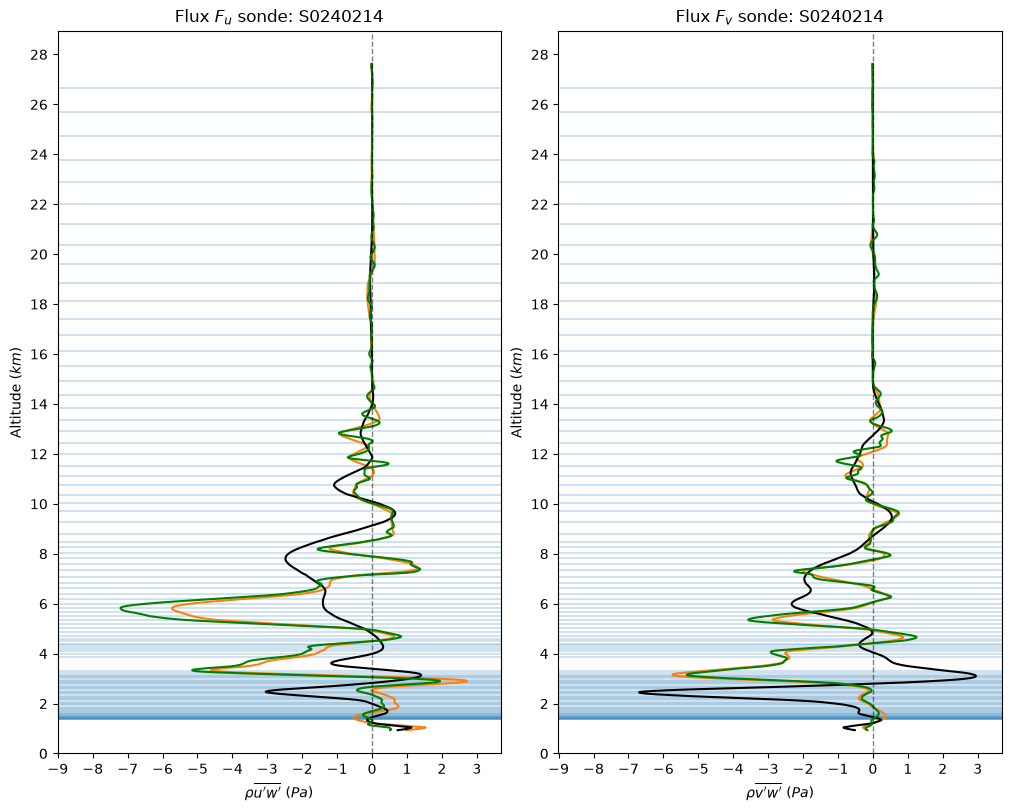

In [ ]:
# =============================================================================
# EXAMPLE USAGE: COMPARE ZONAL AND MERIDIONAL MOMENTUM FLUX PROFILES
# =============================================================================

# Plot the calculated momentum fluxes for the coarsened sonde, model sonde,
# and raw sonde against altitude.
#
# The two panels show the zonal and meridional components separately,
# allowing differences in flux magnitude, sign, and vertical structure
# between the three datasets to be examined.
#
# Model vertical level heights are overlaid to indicate the vertical
# resolution of the model relative to the observed flux structures.

fig = plt.figure(figsize=(10,8), layout="constrained") 
ax = fig.subplots(1,2).flatten()

# Use a common altitude range and horizontal flux scale for both panels.
# The flux limits are determined from the extrema of all six profiles,
# with an additional 25% margin.
#
# Note that these extrema are not NaN-aware, so NaNs in the flux arrays
# may produce invalid axis limits.
ylim = (0,None)

max_flux = np.max(np.array([np.max(Flux_u_s), np.max(Flux_u_m), np.max(Flux_u_r), np.max(Flux_v_s), np.max(Flux_v_m), np.max(Flux_v_r)]))
min_flux = np.min(np.array([np.min(Flux_u_s), np.min(Flux_u_m), np.min(Flux_u_r), np.min(Flux_v_s), np.min(Flux_v_m), np.min(Flux_v_r)]))

xlim = (1.25*min_flux, 1.25*max_flux)
#xlim = (-1e-1, 1e-1)


# =============================================================================
# ZONAL MOMENTUM FLUX
# =============================================================================

# Compare the vertical profiles of zonal momentum flux.
# Orange represents the coarsened sonde, black the model sonde,
# and green the raw sonde.
#
# The vertical reference line distinguishes positive and negative fluxes.

# Plot zonal flux
ax[0].plot(Flux_u_s, alt_km, color="C1")
ax[0].plot(Flux_u_m, alt_km, color="k")
ax[0].plot(Flux_u_r, alt_km, color="green")
ax[0].axvline(0, linestyle="--", linewidth=1, color="k", alpha=0.5)

ax[0].set_xlim(xlim)
ax[0].locator_params(axis="x", nbins=15)
ax[0].set_xlabel(r"$\rho \overline{u^\prime w^\prime}$ ($Pa$)")

ax[0].set_ylim(ylim)
ax[0].locator_params(axis="y", nbins=15)
ax[0].set_ylabel(r"Altitude ($km$)")

ax[0].set_title(rf"Flux $F_u$ sonde: {plot_title_affix}")


# =============================================================================
# MERIDIONAL MOMENTUM FLUX
# =============================================================================

# Repeat the comparison for the meridional momentum flux.
# Identical axis limits allow the relative magnitudes of the zonal
# and meridional components to be compared directly.

#Plot meridional flux
ax[1].plot(Flux_v_s, alt_km, color="C1")
ax[1].plot(Flux_v_m, alt_km, color="k")
ax[1].plot(Flux_v_r, alt_km, color="green")
ax[1].axvline(0, linestyle="--", linewidth=1, color="k", alpha=0.5)

ax[1].set_xlim(xlim)
ax[1].locator_params(axis="x", nbins=15)
ax[1].set_xlabel(r"$\rho \overline{v^\prime w^\prime}$ ($Pa$)")

ax[1].set_ylim(ylim)
ax[1].locator_params(axis="y", nbins=15)
ax[1].set_ylabel(r"Altitude ($km$)")

ax[1].set_title(rf"Flux $F_v$ sonde: {plot_title_affix}")


# =============================================================================
# OVERLAY MODEL VERTICAL LEVELS
# =============================================================================

# Mark the physical heights of the model's vertical levels on both panels.
# These provide context for interpreting differences between the model
# sonde and the observational profiles, particularly where the fluxes
# exhibit vertical variations over scales comparable to the model spacing.
#
# Non-finite level heights are excluded, and heights are converted from
# metres to kilometres to match the altitude axis.

for height in cross_heights:
    if np.isfinite(height):
        ax[0].axhline(height*1e-3, linewidth=0.3, alpha=1, zorder=1)
        ax[1].axhline(height*1e-3, linewidth=0.3, alpha=1, zorder=1)

# Display the comparison. The optional save command is currently disabled.
plt.show()
#plt.savefig(f"Momentum_flux_sonde_id_{plot_title_affix}.png")

In [39]:
# Work out a Flux vector

heading = (180/np.pi * np.arctan(Flux_u_r/Flux_v_r)) + 360
Flux_mag = np.sqrt(Flux_u_r**2 + Flux_v_r**2)

heading = tx.rolling_mean(heading, 100)


In [40]:
# Looking at flux vector and direction
r_cubes = iris.load(cubelist_r_path)

wind_direction_cube = r_cubes.extract_cube("wind_from_direction")
wind_direction_raw = wind_direction_cube.data

wind_mag_cube = r_cubes.extract_cube("wind_speed")
wind_mag_raw = wind_mag_cube.data

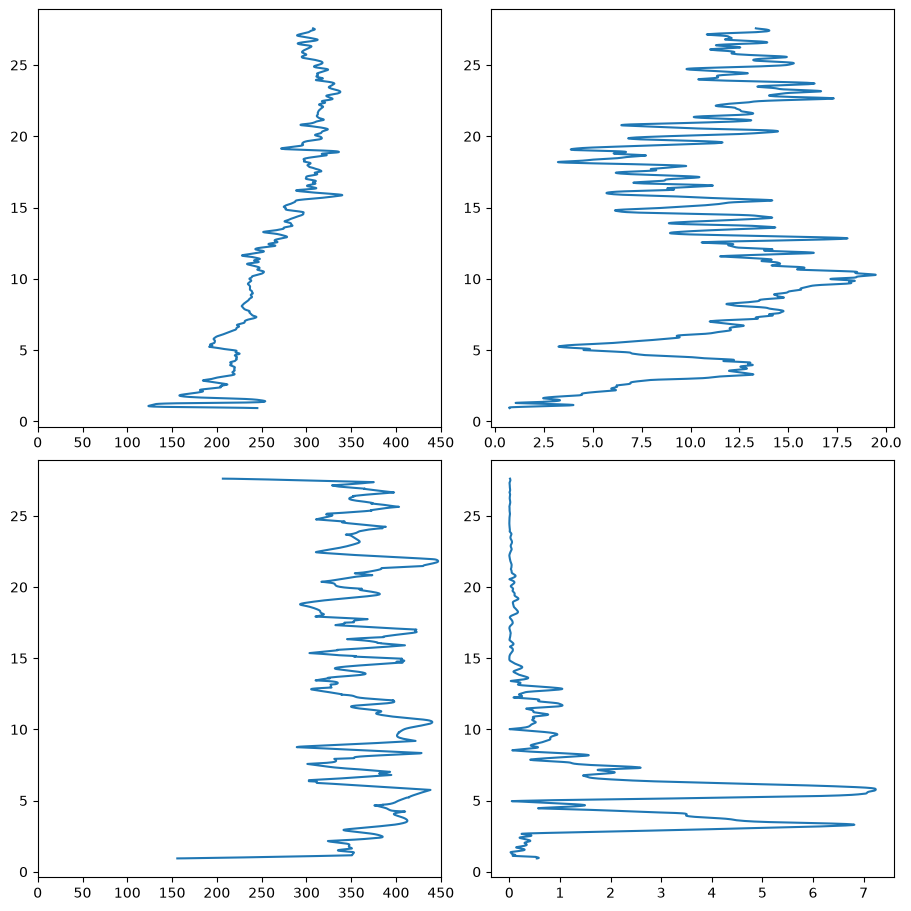

In [41]:
fig = plt.figure(figsize=(9,9), layout="constrained")
ax = fig.subplots(2,2).flatten()

ax[0].plot(wind_direction_raw, alt_km)
ax[0].set_xlim(0, 450)
ax[1].plot(wind_mag_raw, alt_km)
ax[2].plot(heading, alt_km)
ax[2].set_xlim(0, 450)
ax[3].plot(Flux_mag, alt_km)
